In [1]:
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split,
    GridSearchCV
)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor,
    ExtraTreesRegressor,
    VotingRegressor
)
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from xgboost import XGBRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

RANDOM_STATE = 42

## 1.Import and Load the Data


In [2]:
df = pd.read_csv("/Users/bigmac/Documents/Data_Science/ML-Projects/Medical-Insuarance-Cost-Predictor/medical_insurance.csv")

In [3]:
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


In [5]:
df.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


In [6]:
df.isnull().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

In [7]:
df.duplicated().sum()

np.int64(1)

## 2. Exploratory Data Analysis (EDA)


### Visualize the distribution of each feature


### Analyze the Numerical variables:

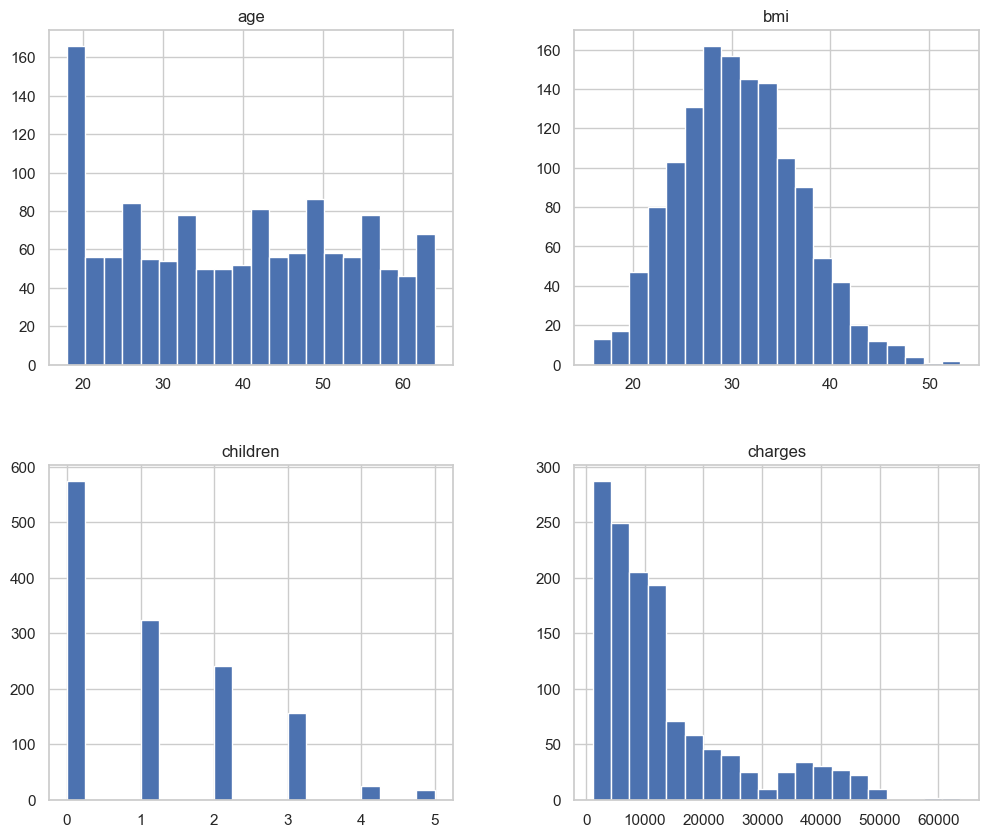

In [8]:
numeric_features = df.select_dtypes(include=[np.number]).columns.tolist()
df[numeric_features].hist(figsize=(12, 10), bins=20)
plt.show()

### Analyze the categorical variables:

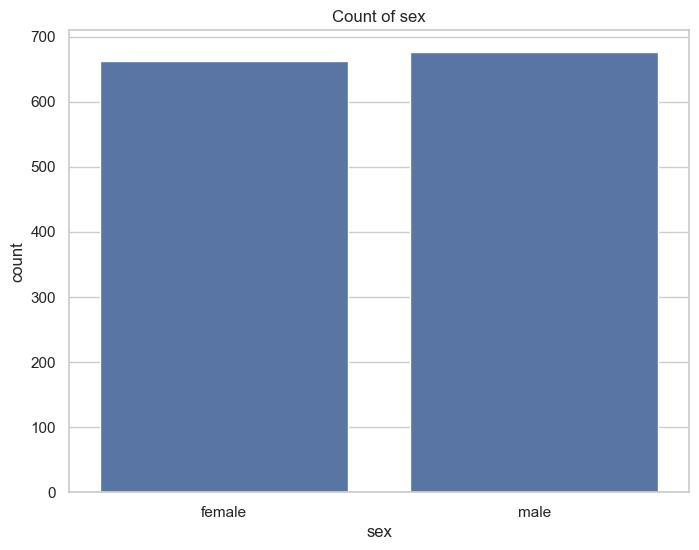

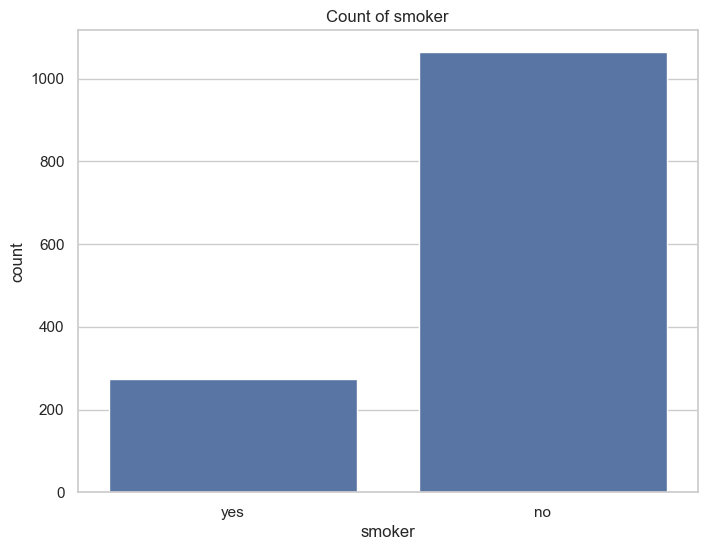

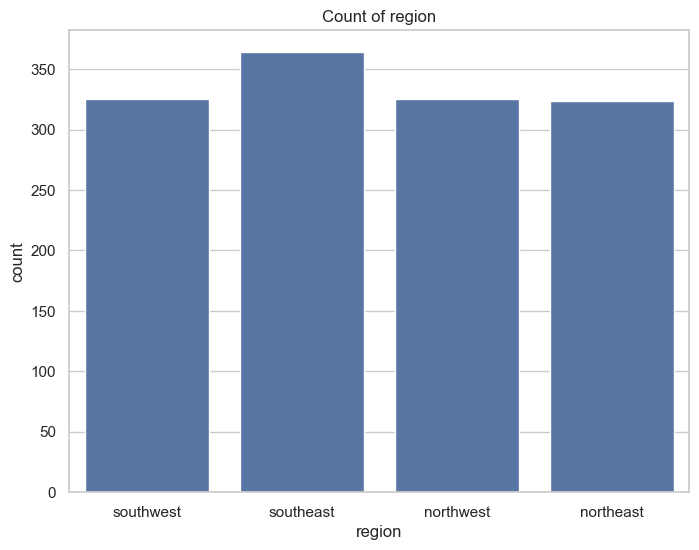

In [9]:
categorical_features = df.select_dtypes(include=[object]).columns.tolist()
for feature in categorical_features:
    plt.figure(figsize=(8, 6))
    sns.countplot(data=df, x=feature)
    plt.title(f"Count of {feature}")
    plt.show()

### Explore The Target variable Charges

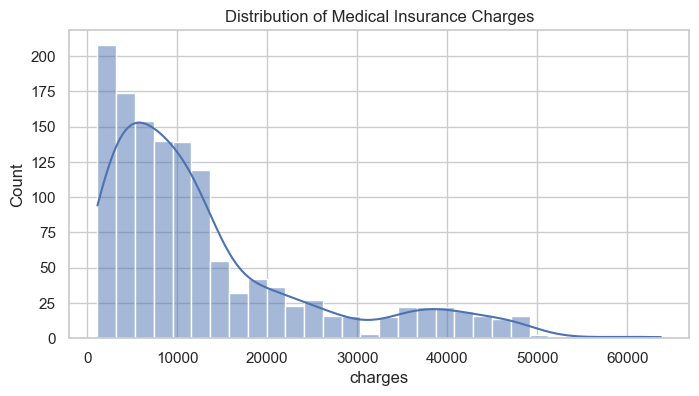

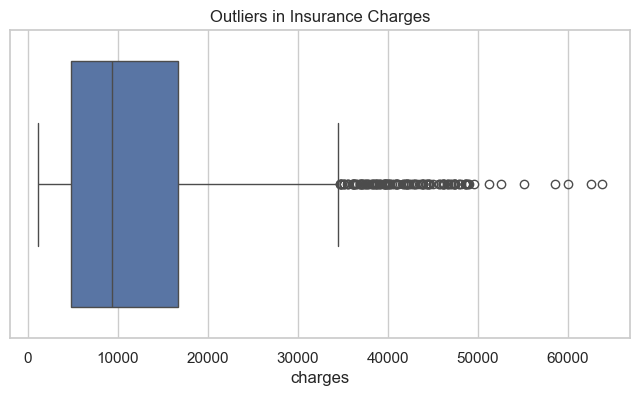

In [10]:
plt.figure(figsize=(8, 4))
sns.histplot(data=df, x="charges", kde=True)
plt.title("Distribution of Medical Insurance Charges")
plt.show()

plt.figure(figsize=(8, 4))
sns.boxplot(data=df, x="charges")
plt.title("Outliers in Insurance Charges")
plt.show()

### Check the relationship between numerical features and charges:

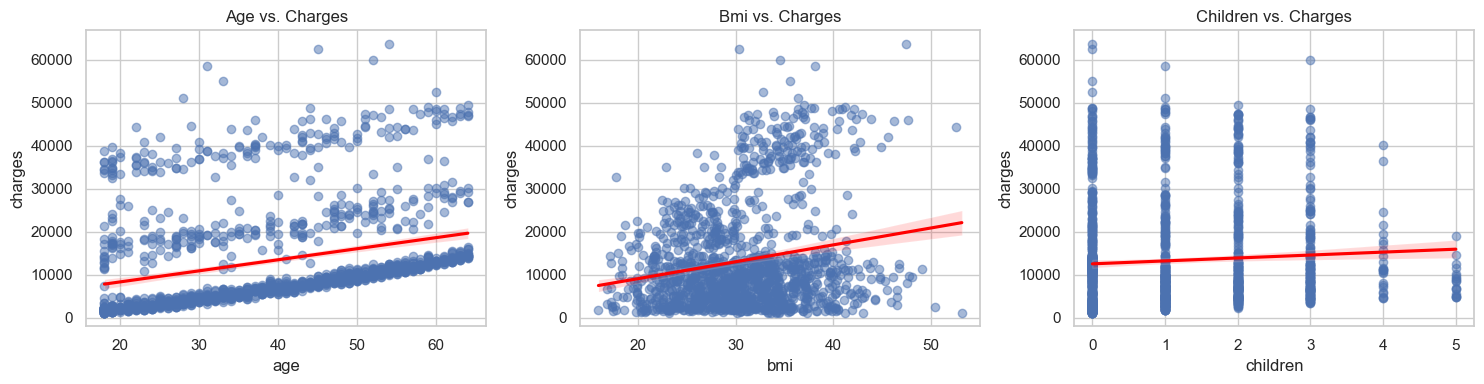

In [11]:
features_to_plot = [feature for feature in numeric_features if feature != "charges"]

fig, axes = plt.subplots(1, len(features_to_plot), figsize=(15, 4))

for ax, feature in zip(axes, features_to_plot):
    sns.regplot(
        data=df,
        x=feature,
        y="charges",
        ax=ax,
        scatter_kws={"alpha": 0.5},
        line_kws={"color": "red"}
    )
    ax.set_title(f"{feature.title()} vs. Charges")

plt.tight_layout()
plt.show()

### Check the influence of smoking status:

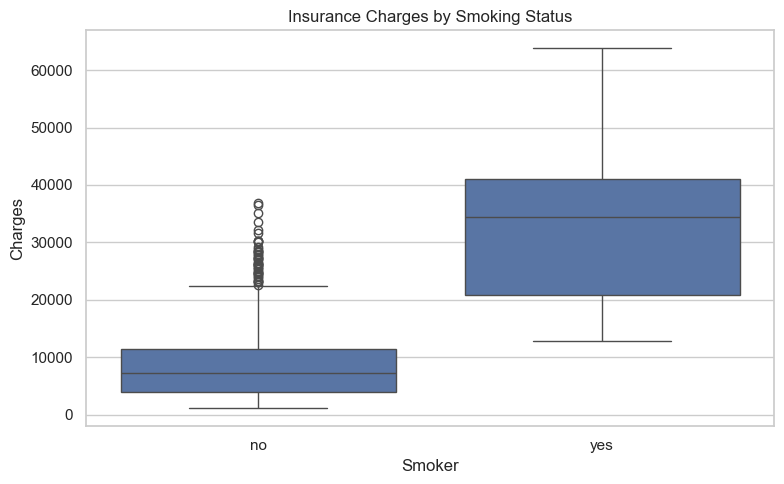

In [12]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="smoker", y="charges", order=["no", "yes"])
plt.title("Insurance Charges by Smoking Status")
plt.xlabel("Smoker")
plt.ylabel("Charges")
plt.tight_layout()
plt.show()

### Summarizing insights from EDA


## EDA Summary and Key Insights

Based on the exploratory data analysis, the following observations were identified:

### 1. Age
- Age is an important numerical feature.
- Insurance charges generally tend to increase with age.
- Older individuals may have higher insurance costs.

### 2. BMI
- BMI shows a relationship with medical insurance charges.
- Individuals with higher BMI may have higher insurance expenses.
- Further analysis can help identify whether the relationship differs by smoking status.

### 3. Smoking Status
- Smoking status is an important categorical feature.
- Smokers generally have considerably higher average insurance charges than non-smokers.
- Smoking status may be an important predictor of insurance costs.

### 4. Gender
- Insurance charges can be compared across male and female policyholders.
- Any observed difference should be evaluated using the actual group averages.

### 5. Number of Children
- The number of children may influence insurance costs.
- The relationship should be examined using average charges for each children category.

### 6. Region
- Insurance charges can vary across residential regions.
- Regional differences should be investigated using group-wise average charges.

### 7. Distribution and Outliers
- Numerical features have different distributions.
- The target variable `charges` should be checked for skewness.
- Box plots help identify extreme observations.
- Outliers should be investigated before deciding whether to remove or transform them.

### 8. Correlation Analysis
- Correlation analysis helps identify linear relationships between numerical features and insurance charges.
- Categorical variables also need to be evaluated because correlation alone does not capture all their relationships with the target.

### Overall Conclusion

EDA helps identify important patterns in medical insurance costs. Age, BMI, and smoking status are useful features to investigate when predicting insurance charges.

The findings will guide the next stages of feature engineering, preprocessing, regression model building, and model evaluation.

##  3.Missing Values & Outlier Treatment


### Handle missing values and duplicates

In [13]:
df.duplicated().sum()

np.int64(1)

In [14]:
df.drop_duplicates(inplace=True)

In [15]:
df.duplicated().sum()

np.int64(0)

In [16]:
df.isnull().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

### Outliers

### By IQR Method

In [17]:
Q1 = df["charges"].quantile(0.25)
Q3 = df["charges"].quantile(0.75)
IQR = Q3 - Q1

In [18]:
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

In [19]:
outliers = df[(df["charges"] < lower_bound) | (df["charges"] > upper_bound)]
outliers

,age,sex,bmi,children,smoker,region,charges
14,27,male,42.130,0,yes,southeast,39611.75770
19,30,male,35.300,0,yes,southwest,36837.46700
23,34,female,31.920,1,yes,northeast,37701.87680
29,31,male,36.300,2,yes,southwest,38711.00000
30,22,male,35.600,0,yes,southwest,35585.57600
...,...,...,...,...,...,...,...
1300,45,male,30.360,0,yes,southeast,62592.87309
1301,62,male,30.875,3,yes,northwest,46718.16325
1303,43,male,27.800,0,yes,southwest,37829.72420
1313,19,female,34.700,2,yes,southwest,36397.57600


### By Box Plot

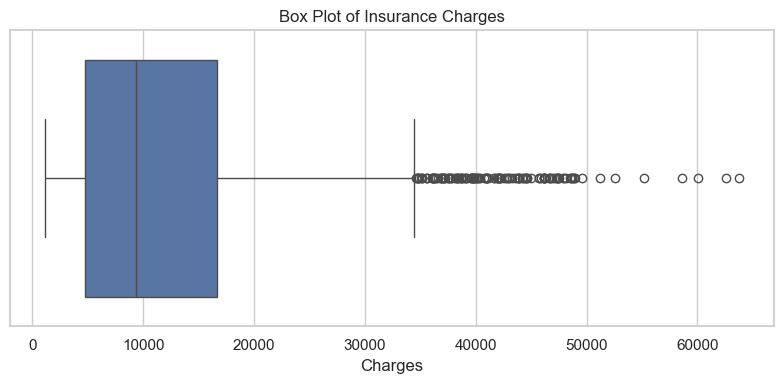

In [20]:
plt.figure(figsize=(8, 4))
sns.boxplot(data=df, x="charges")
plt.title("Box Plot of Insurance Charges")
plt.xlabel("Charges")
plt.tight_layout()
plt.show()

## 4. Feature Engineering & Preprocessing


### Saperating Features and Target

In [21]:
target = "charges"
X = df.drop(columns=[target])
y = df[target]

In [22]:
X

,age,sex,bmi,children,smoker,region
0,19,female,27.900,0,yes,southwest
1,18,male,33.770,1,no,southeast
2,28,male,33.000,3,no,southeast
3,33,male,22.705,0,no,northwest
4,32,male,28.880,0,no,northwest
...,...,...,...,...,...,...
1333,50,male,30.970,3,no,northwest
1334,18,female,31.920,0,no,northeast
1335,18,female,36.850,0,no,southeast
1336,21,female,25.800,0,no,southwest


In [23]:
y

0       16884.92400
1        1725.55230
2        4449.46200
3       21984.47061
4        3866.85520
           ...     
1333    10600.54830
1334     2205.98080
1335     1629.83350
1336     2007.94500
1337    29141.36030
Name: charges, Length: 1337, dtype: float64

### Data splitting and Preprocessing

In [24]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)

X_train = pd.get_dummies(X_train, columns=categorical_features, drop_first=True, dtype=int)
X_test = pd.get_dummies(X_test, columns=categorical_features, drop_first=True, dtype=int)
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

numeric_columns = ["age", "bmi", "children"]
scaler = StandardScaler()
X_train.loc[:, numeric_columns] = scaler.fit_transform(X_train[numeric_columns])
X_test.loc[:, numeric_columns] = scaler.transform(X_test[numeric_columns])

print("Training features:", X_train.shape)
print("Test features:", X_test.shape)

Training features: (1069, 8)
Test features: (268, 8)


/var/folders/2t/n6vg3tc12tb9jclwgbxwfzvc0000gn/T/ipykernel_1810/1333931321.py:11: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[-1.1576804  -1.30061876  0.91492586 ... -1.37208794 -0.08564268
 -0.30005022]' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  X_train.loc[:, numeric_columns] = scaler.fit_transform(X_train[numeric_columns])
/var/folders/2t/n6vg3tc12tb9jclwgbxwfzvc0000gn/T/ipykernel_1810/1333931321.py:11: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[-0.90790804  0.7669042   0.7669042  ... -0.07050192  1.60431032
  0.7669042 ]' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  X_train.loc[:, numeric_columns] = scaler.fit_transform(X_train[numeric_columns])
/var/folders/2t/n6vg3tc12tb9jclwgbxwfzvc0000gn/T/ipykernel_1810/1333931321.py:12: FutureWarning: Set

### Check for skewness and treat it if required.


In [25]:
skewness = X_train[numeric_columns].skew()
    

In [26]:
skewness

age         0.066010
bmi         0.318271
children    0.952955
dtype: float64

## 5. Model Building: Try Multiple Regressors


Use all the regression-based models to train and test the data:

Linear Regression

Decision Tree Regressor

Random Forest Regressor

SVR

KNN

Ensemble Learning methods


In [27]:
models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(random_state=RANDOM_STATE),
    "Random Forest": RandomForestRegressor(random_state=RANDOM_STATE),
    "Gradient Boosting": GradientBoostingRegressor(random_state=RANDOM_STATE),
    "Extra Trees": ExtraTreesRegressor(random_state=RANDOM_STATE),
    "Support Vector Regressor": SVR(),
    "K-Nearest Neighbors": KNeighborsRegressor()  ,
    "XGBoost Regressor": XGBRegressor(random_state=RANDOM_STATE)
}         

In [28]:
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    

In [29]:
y

0       16884.92400
1        1725.55230
2        4449.46200
3       21984.47061
4        3866.85520
           ...     
1333    10600.54830
1334     2205.98080
1335     1629.83350
1336     2007.94500
1337    29141.36030
Name: charges, Length: 1337, dtype: float64

## 6. Model Evaluation & Overfitting Check


### Use metrics:
Mean Absolute Error (MAE)

Mean Squared Error (MSE)

Root Mean Squared Error (RMSE)

R² Score

Adjusted R² Score


In [30]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)
adjusted_r2 = 1 - (1 - r2) * (len(y_test) - 1) / (len(y_test) - X_test.shape[1] - 1)
    
print(f"{name}:")
print(f"  Mean Absolute Error: {mae:.2f}")
print(f"  Mean Squared Error: {mse:.2f}")
print(f"  Root Mean Squared Error: {rmse:.2f}")
print(f"  R-squared: {r2:.4f}")
print(f"  Adjusted R-squared: {adjusted_r2:.4f}\n")

XGBoost Regressor:
  Mean Absolute Error: 2922.40
  Mean Squared Error: 24786419.95
  Root Mean Squared Error: 4978.60
  R-squared: 0.8651
  Adjusted R-squared: 0.8609



### Visualize model comparison

,MAE,RMSE,R²,Adjusted R²
Model,,,,
Gradient Boosting,2517.467831,4268.283018,0.900856,0.897794
Random Forest,2663.328798,4729.965694,0.878249,0.874488
XGBoost Regressor,2922.399640,4978.596183,0.865112,0.860946
Extra Trees,2703.081823,5218.607550,0.851793,0.847216
Decision Tree,2804.811633,5912.108673,0.809786,0.803910
Linear Regression,4177.045561,5956.342894,0.806929,0.800965
K-Nearest Neighbors,4496.305289,8062.696944,0.646232,0.635304
Support Vector Regressor,9261.820814,14431.116774,-0.133335,-0.168341


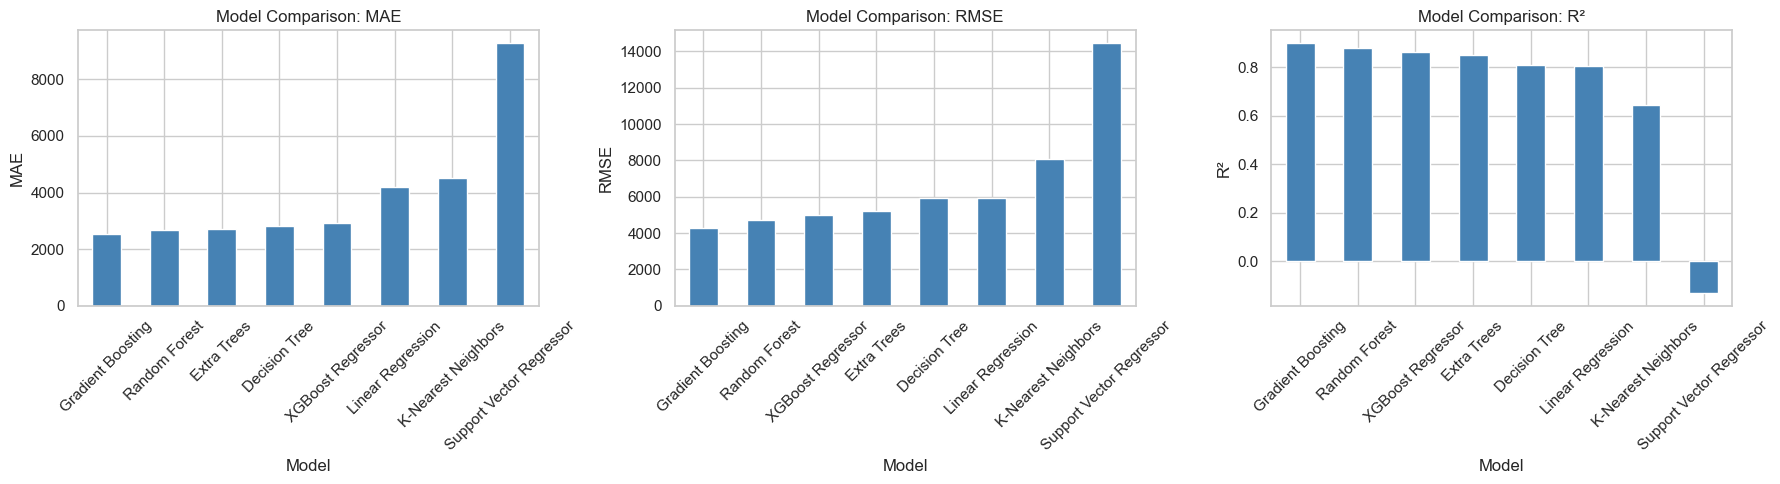

In [31]:
# Evaluate each model on the same test set
comparison_results = []

for model_name, estimator in models.items():
    estimator.fit(X_train, y_train)
    predictions = estimator.predict(X_test)

    mae_value = mean_absolute_error(y_test, predictions)
    mse_value = mean_squared_error(y_test, predictions)
    r2_value = r2_score(y_test, predictions)
    adjusted_r2_value = 1 - (1 - r2_value) * (len(y_test) - 1) / (
        len(y_test) - X_test.shape[1] - 1
    )

    comparison_results.append({
        "Model": model_name,
        "MAE": mae_value,
        "RMSE": np.sqrt(mse_value),
        "R²": r2_value,
        "Adjusted R²": adjusted_r2_value
    })

model_comparison = pd.DataFrame(comparison_results).set_index("Model")
display(model_comparison.sort_values("RMSE"))

# Compare metrics; lower MAE/RMSE and higher R² are better
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, metric in zip(axes, ["MAE", "RMSE", "R²"]):
    values = model_comparison[metric].sort_values(
        ascending=(metric != "R²")
    )
    values.plot(kind="bar", ax=ax, color="steelblue")
    ax.set_title(f"Model Comparison: {metric}")
    ax.set_ylabel(metric)
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

## 7. Hyperparameter Tuning
Use GridSearchCV or RandomizedSearchCV to optimize the best-performing models
Document best parameters and improvement in performance


In [32]:
baseline_model = GradientBoostingRegressor(random_state=RANDOM_STATE)
baseline_model.fit(X_train, y_train)
baseline_predictions = baseline_model.predict(X_test)
baseline_rmse = np.sqrt(mean_squared_error(y_test, baseline_predictions))


param_grid = {
    "n_estimators": [100, 200],
    "learning_rate": [0.03, 0.05, 0.1],
    "max_depth": [2, 3],
    "min_samples_leaf": [1, 3],
}

grid_search = GridSearchCV(
    estimator=GradientBoostingRegressor(random_state=RANDOM_STATE),
    param_grid=param_grid,
    scoring="neg_root_mean_squared_error",
    cv=5,
    n_jobs=-1,
    refit=True
)
grid_search.fit(X_train, y_train)


tuned_model = grid_search.best_estimator_
tuned_predictions = tuned_model.predict(X_test)
tuned_rmse = np.sqrt(mean_squared_error(y_test, tuned_predictions))
tuned_r2 = r2_score(y_test, tuned_predictions)
rmse_improvement = baseline_rmse - tuned_rmse
improvement_percent = 100 * rmse_improvement / baseline_rmse

print("Best parameters:", grid_search.best_params_)
print(f"Best cross-validation RMSE: {-grid_search.best_score_:.2f}")
print(f"Baseline test RMSE:         {baseline_rmse:.2f}")
print(f"Tuned test RMSE:            {tuned_rmse:.2f}")
print(f"Tuned test R²:              {tuned_r2:.4f}")
print(f"Test RMSE improvement:      {rmse_improvement:.2f} ({improvement_percent:.2f}%)")

Best parameters: {'learning_rate': 0.05, 'max_depth': 3, 'min_samples_leaf': 3, 'n_estimators': 100}
Best cross-validation RMSE: 4606.39
Baseline test RMSE:         4268.28
Tuned test RMSE:            4250.78
Tuned test R²:              0.9017
Test RMSE improvement:      17.51 (0.41%)


## 8. Model Comparison Table


In [33]:
tuned_mae = mean_absolute_error(y_test, tuned_predictions)
tuned_adjusted_r2 = 1 - (1 - tuned_r2) * (len(y_test) - 1) / (
    len(y_test) - X_test.shape[1] - 1
)

final_comparison = model_comparison.copy()
final_comparison.loc["Tuned Gradient Boosting"] = {
    "MAE": tuned_mae,
    "RMSE": tuned_rmse,
    "R²": tuned_r2,
    "Adjusted R²": tuned_adjusted_r2
}

display(final_comparison.sort_values("RMSE").round(4))

,MAE,RMSE,R²,Adjusted R²
Model,,,,
Tuned Gradient Boosting,2491.6900,4250.7770,0.9017,0.8986
Gradient Boosting,2517.4678,4268.2830,0.9009,0.8978
Random Forest,2663.3288,4729.9657,0.8782,0.8745
XGBoost Regressor,2922.3996,4978.5962,0.8651,0.8609
Extra Trees,2703.0818,5218.6075,0.8518,0.8472
Decision Tree,2804.8116,5912.1087,0.8098,0.8039
Linear Regression,4177.0456,5956.3429,0.8069,0.8010
K-Nearest Neighbors,4496.3053,8062.6969,0.6462,0.6353
Support Vector Regressor,9261.8208,14431.1168,-0.1333,-0.1683


In [34]:
best_model = tuned_model
best_model

GradientBoostingRegressor(learning_rate=0.05, min_samples_leaf=3,
                          random_state=42)